# Lab 05:  PCA of land-cover patches

**Data.** Same Sentinel-2 tiles as Labs 2–4 (`scenes/`):
- **forest** - `s2_natural_*` (Puszcza)
- **man-made** - built-up parts of `s2_urban_*` (Kraków)
- **water/ocean** - open-water pixels in the urban tile (Vistula; used as a water/ocean spectral proxy)

Bands: B02, B03, B04, B08.


forest tile (512, 512, 4), urban tile (512, 512, 4)
mask pixels — forest: 233404 | man-made: 106251 | water: 23041


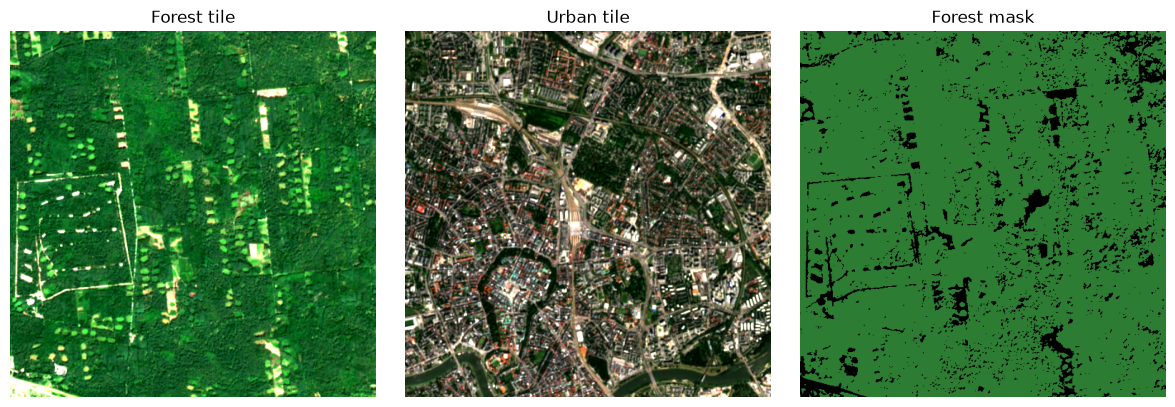

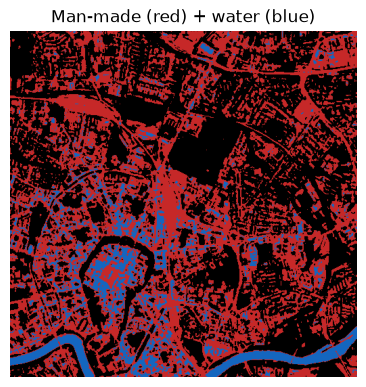

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
DATA = ROOT / "scenes" if (ROOT / "scenes").exists() else ROOT.parent / "scenes"
BANDS = ["B02", "B03", "B04", "B08"]
FOREST, URBAN, WATER = 0, 1, 2
NAMES = {FOREST: "forest", URBAN: "man-made", WATER: "water/ocean"}
COLORS = {FOREST: "#2e7d32", URBAN: "#c62828", WATER: "#1565c0"}


def load_stack(prefix: str) -> np.ndarray:
    bands = []
    for b in BANDS:
        with rasterio.open(DATA / f"{prefix}_{b}.tif") as src:
            bands.append(src.read(1).astype(np.float32))
    return np.stack(bands, axis=-1)


def ndvi(img: np.ndarray) -> np.ndarray:
    nir, red = img[..., 3], img[..., 2]
    return (nir - red) / (nir + red + 1e-6)


def rgb_preview(img: np.ndarray) -> np.ndarray:
    rgb = img[..., [2, 1, 0]].astype(np.float32)
    lo, hi = np.percentile(rgb, (2, 98))
    return np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)


forest = load_stack("s2_natural")
urban = load_stack("s2_urban")
ndvi_f, ndvi_u = ndvi(forest), ndvi(urban)
nir_u = urban[..., 3]

forest_mask = ndvi_f > 0.42
water_mask = (nir_u < np.percentile(nir_u, 15)) & (ndvi_u < 0.08)
urban_mask = (~water_mask) & (ndvi_u < 0.22)

print(f"forest tile {forest.shape}, urban tile {urban.shape}")
print(
    "mask pixels — forest:", int(forest_mask.sum()),
    "| man-made:", int(urban_mask.sum()),
    "| water:", int(water_mask.sum()),
)

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(rgb_preview(forest)); ax[0].set_title("Forest tile"); ax[0].axis("off")
ax[1].imshow(rgb_preview(urban)); ax[1].set_title("Urban tile"); ax[1].axis("off")
f_ov = np.zeros((*forest_mask.shape, 3))
f_ov[forest_mask] = [0.18, 0.49, 0.20]
ax[2].imshow(f_ov); ax[2].set_title("Forest mask"); ax[2].axis("off")
fig.tight_layout()
plt.show()

overlay = np.zeros((*urban_mask.shape, 3))
overlay[urban_mask] = [0.78, 0.16, 0.16]
overlay[water_mask] = [0.08, 0.40, 0.75]
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(overlay); ax.set_title("Man-made (red) + water (blue)"); ax.axis("off")
plt.show()


forest       patches: 930
man-made     patches: 85
water/ocean  patches: 44
patch matrix Xf=(1059, 1024), labels=[930  85  44]
forest       pixels:  2500
man-made     pixels:  2500
water/ocean  pixels:  2500


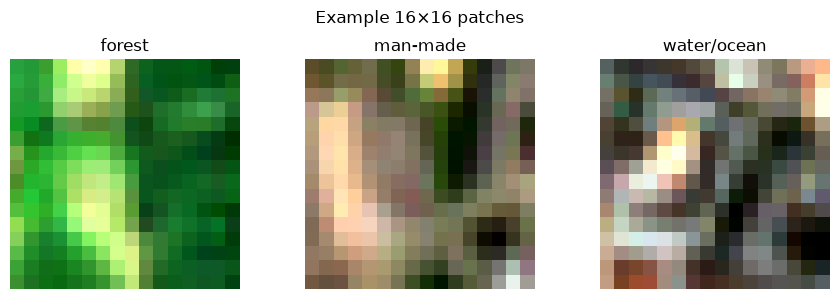

In [2]:
def extract_patches(img, label, mask=None, patch=16, stride=16, min_frac=0.6):
    h, w, _ = img.shape
    xs, ys = [], []
    for r in range(0, h - patch + 1, stride):
        for c in range(0, w - patch + 1, stride):
            if mask is not None and mask[r : r + patch, c : c + patch].mean() < min_frac:
                continue
            xs.append(img[r : r + patch, c : c + patch])
            ys.append(label)
    return xs, ys


def sample_pixels(img, mask, label, n=2500, rng=None):
    rng = rng or np.random.default_rng(0)
    idx = np.argwhere(mask)
    if len(idx) > n:
        idx = idx[rng.choice(len(idx), size=n, replace=False)]
    return img[idx[:, 0], idx[:, 1]], np.full(len(idx), label, dtype=np.int8)


rng = np.random.default_rng(42)
PATCH, STRIDE = 16, 16

X_list, y_list = [], []
for img, lab, mask, mf in [
    (forest, FOREST, forest_mask, 0.7),
    (urban, URBAN, urban_mask, 0.7),
    (urban, WATER, water_mask, 0.45), 
]:
    xs, ys = extract_patches(img, lab, mask, PATCH, STRIDE, mf)
    X_list.extend(xs)
    y_list.extend(ys)
    print(f"{NAMES[lab]:12s} patches: {len(xs)}")

Xp = np.stack(X_list)
yp = np.asarray(y_list)
Xf = Xp.reshape(len(Xp), -1)  # N × 1024
print(f"patch matrix Xf={Xf.shape}, labels={np.bincount(yp)}")

px, py = [], []
for img, lab, mask in [
    (forest, FOREST, forest_mask),
    (urban, URBAN, urban_mask),
    (urban, WATER, water_mask),
]:
    a, b = sample_pixels(img, mask, lab, n=2500, rng=rng)
    px.append(a)
    py.append(b)
    print(f"{NAMES[lab]:12s} pixels:  {len(b)}")

Px = np.concatenate(px)
Py = np.concatenate(py)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for i, lab in enumerate((FOREST, URBAN, WATER)):
    j = np.where(yp == lab)[0][0]
    ax[i].imshow(rgb_preview(Xp[j]))
    ax[i].set_title(NAMES[lab])
    ax[i].axis("off")
fig.suptitle("Example 16×16 patches")
fig.tight_layout()
plt.show()


Pixel PCA explained variance: [0.7428 0.2418 0.0123] cum= 0.9969
Patch PCA explained variance: [0.5941 0.095  0.0356] cum= 0.7247


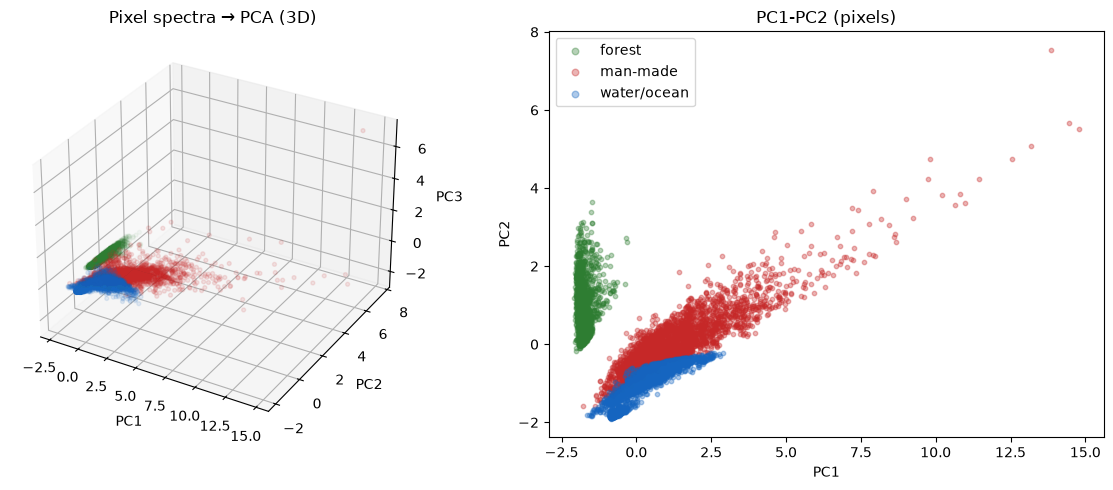

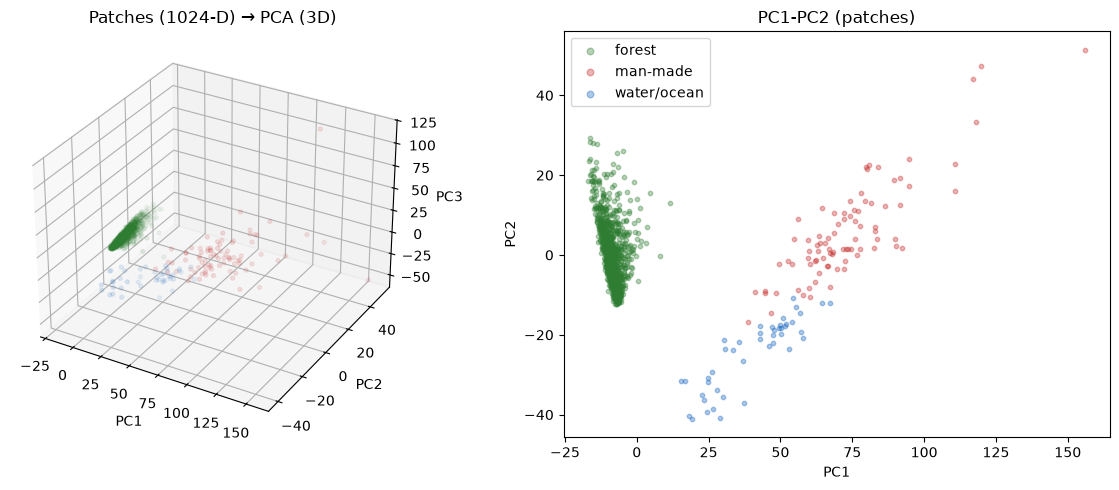

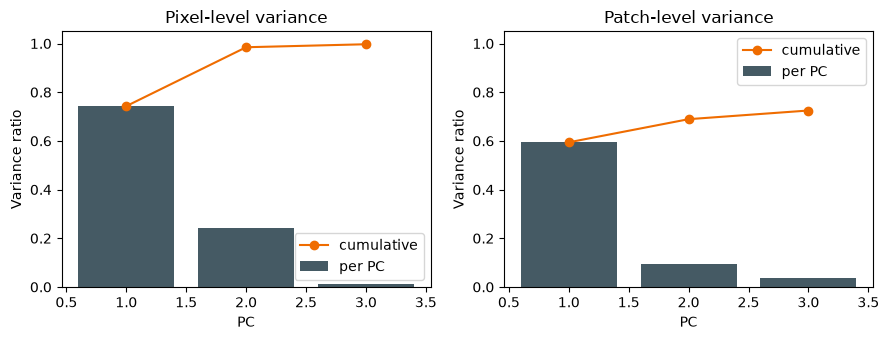

In [3]:
scaler_pix = StandardScaler()
Zp = scaler_pix.fit_transform(Px)
pca_pix = PCA(n_components=3, random_state=0)
Pc_pix = pca_pix.fit_transform(Zp)

scaler_pat = StandardScaler()
Zf = scaler_pat.fit_transform(Xf)
pca_pat = PCA(n_components=3, random_state=0)
Pc_pat = pca_pat.fit_transform(Zf)

print(
    "Pixel PCA explained variance:",
    np.round(pca_pix.explained_variance_ratio_, 4),
    "cum=",
    round(float(pca_pix.explained_variance_ratio_.sum()), 4),
)
print(
    "Patch PCA explained variance:",
    np.round(pca_pat.explained_variance_ratio_, 4),
    "cum=",
    round(float(pca_pat.explained_variance_ratio_.sum()), 4),
)


def plot_pca(Pc, labels, title_3d, title_2d):
    fig = plt.figure(figsize=(12, 5))
    ax3 = fig.add_subplot(121, projection="3d")
    ax2 = fig.add_subplot(122)
    dense = Pc.shape[0] > 500
    for lab in (FOREST, URBAN, WATER):
        m = labels == lab
        if not np.any(m):
            continue
        ax3.scatter(
            Pc[m, 0], Pc[m, 1], Pc[m, 2],
            s=8 if dense else 28,
            alpha=0.35 if dense else 0.8,
            c=COLORS[lab],
            label=NAMES[lab],
        )
        ax2.scatter(
            Pc[m, 0], Pc[m, 1],
            s=10 if dense else 36,
            alpha=0.35 if dense else 0.8,
            c=COLORS[lab],
            label=NAMES[lab],
        )
    ax3.set_xlabel("PC1"); ax3.set_ylabel("PC2"); ax3.set_zlabel("PC3")
    ax3.set_title(title_3d)
    ax2.set_xlabel("PC1"); ax2.set_ylabel("PC2"); ax2.set_title(title_2d)
    ax2.legend(markerscale=1.5)
    fig.tight_layout()
    plt.show()


plot_pca(Pc_pix, Py, "Pixel spectra → PCA (3D)", "PC1-PC2 (pixels)")
plot_pca(Pc_pat, yp, "Patches (1024-D) → PCA (3D)", "PC1-PC2 (patches)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
for ax_i, pca, title in [
    (ax[0], pca_pix, "Pixel-level variance"),
    (ax[1], pca_pat, "Patch-level variance"),
]:
    r = pca.explained_variance_ratio_
    ax_i.bar(range(1, len(r) + 1), r, color="#455a64", label="per PC")
    ax_i.plot(range(1, len(r) + 1), np.cumsum(r), "o-", color="#ef6c00", label="cumulative")
    ax_i.set_xlabel("PC"); ax_i.set_ylabel("Variance ratio"); ax_i.set_title(title)
    ax_i.set_ylim(0, 1.05)
    ax_i.legend()
fig.tight_layout()
plt.show()
